# Cyclistic Bike Share Analysis

## Notebook 2 - Cleaning merged dataset

Objective:
Clean the merged Cyclist trip data and create an analysis-ready dataset

Input: 00_Data/01_Interim/cyclistic_202506_202605_merged.parquet

Output: 00_Data/01_Interim/cyclistic_202506_202605_cleaned.parquet

### Import libraries and merged dataset

In [1]:
# Import libraries

import numpy as np
import pandas as pd
from pathlib import Path

In [2]:
# Import merged dataset

df = pd.read_parquet(
    "../00_Data/01_Interim/cyclistic_202506_202605_merged.parquet"
)

### Data quality assessment

In [3]:
df.shape

(5848703, 13)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5848703 entries, 0 to 5848702
Data columns (total 13 columns):
 #   Column              Dtype  
---  ------              -----  
 0   ride_id             object 
 1   rideable_type       object 
 2   started_at          object 
 3   ended_at            object 
 4   start_station_name  object 
 5   start_station_id    object 
 6   end_station_name    object 
 7   end_station_id      object 
 8   start_lat           float64
 9   start_lng           float64
 10  end_lat             float64
 11  end_lng             float64
 12  member_casual       object 
dtypes: float64(4), object(9)
memory usage: 580.1+ MB


"started_at" and "ended_at" are recognized as string datatype.
Further conversion needed.

In [5]:
# Null value check

df.isna().sum()

ride_id                     0
rideable_type               0
started_at                  0
ended_at                    0
start_station_name    1249667
start_station_id      1249667
end_station_name      1314334
end_station_id        1314334
start_lat                   0
start_lng                   0
end_lat                  5896
end_lng                  5896
member_casual               0
dtype: int64

In [6]:
# Duplicated entries check

df.duplicated().sum()

np.int64(35)

In [12]:
# Check "member_causal" only contains "member" and "casual"

assert set(df["member_casual"]) == {"member", "casual"}

df["member_casual"].value_counts()

member_casual
member    3748438
casual    2100265
Name: count, dtype: int64

In [14]:
# Check "rideable_type"

assert set(df["rideable_type"]) == {"classic_bike", "electric_bike"}

df["rideable_type"].value_counts()

rideable_type
electric_bike    3902512
classic_bike     1946191
Name: count, dtype: int64

### Summary of Datetime conversion

- Converted "started_at" and "ended_at" from object to datetime64[ns], using 'pd.to_timedate(errors="coerce")'.

- This ensures compatibility with time-based feature engineering and aggregations.

- Validated by ".info()" and ".isna().sum()"

In [7]:
# Convert "started_at" and "ended_at" from object to datetime64[ns]

df["started_at"] = pd.to_datetime(
    df["started_at"],
    errors="coerce"
)

df["ended_at"] = pd.to_datetime(
    df["ended_at"],
    errors="coerce"
)

In [8]:
# Validation

df.info()

df[["started_at", "ended_at"]].isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5848703 entries, 0 to 5848702
Data columns (total 13 columns):
 #   Column              Dtype         
---  ------              -----         
 0   ride_id             object        
 1   rideable_type       object        
 2   started_at          datetime64[ns]
 3   ended_at            datetime64[ns]
 4   start_station_name  object        
 5   start_station_id    object        
 6   end_station_name    object        
 7   end_station_id      object        
 8   start_lat           float64       
 9   start_lng           float64       
 10  end_lat             float64       
 11  end_lng             float64       
 12  member_casual       object        
dtypes: datetime64[ns](2), float64(4), object(7)
memory usage: 580.1+ MB


started_at    0
ended_at      0
dtype: int64

### Summary of Duplicated records

Finding
- 35 trips have duplicated "ride_id"

Interpretation/Decision
- The "ride_id" field is expected to be unique for each ride. Any duplicated records (records with the same ride_id) are being removed by using "drop_duplicates()".

In [9]:
# Inspecting duplicate entries

df["ride_id"].duplicated().sum()

np.int64(35)

In [10]:
duplicates = df[df.duplicated(keep=False)]

duplicates.sort_values("ride_id").head(20)

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
4990860,03C5375398BE0649,electric_bike,2026-04-30 23:46:36.039,2026-05-01 00:04:48.512,None,None,Clark St & Arlington Pl,CHI02109,41.900000,-87.630000,41.926940,-87.641480,member
5731714,03C5375398BE0649,electric_bike,2026-04-30 23:46:36.039,2026-05-01 00:04:48.512,None,None,Clark St & Arlington Pl,CHI02109,41.900000,-87.630000,41.926940,-87.641480,member
5112192,0612B2A21BA5E988,classic_bike,2026-04-30 15:56:11.305,2026-05-01 16:56:08.148,Fulton Market,CHI01880,None,None,41.886871,-87.648089,NaN,NaN,member
5454773,0612B2A21BA5E988,classic_bike,2026-04-30 15:56:11.305,2026-05-01 16:56:08.148,Fulton Market,CHI01880,None,None,41.886871,-87.648089,NaN,NaN,member
5346781,10117825A92C182D,classic_bike,2026-04-30 23:56:24.321,2026-05-01 00:01:51.860,Peoria St & Kinzie St,CHI02098,Ogden Ave & Chicago Ave,CHI00275,41.888960,-87.649730,41.896362,-87.654061,casual
4931419,10117825A92C182D,classic_bike,2026-04-30 23:56:24.321,2026-05-01 00:01:51.860,Peoria St & Kinzie St,CHI02098,Ogden Ave & Chicago Ave,CHI00275,41.888960,-87.649730,41.896362,-87.654061,casual
4863609,15521787039F37E5,classic_bike,2026-04-30 23:54:44.934,2026-05-01 00:05:45.575,Michigan Ave & 11th St,CHI02025,DuSable Lake Shore Dr & Monroe St,CHI00374,41.869590,-87.623961,41.880958,-87.616743,member
5613023,15521787039F37E5,classic_bike,2026-04-30 23:54:44.934,2026-05-01 00:05:45.575,Michigan Ave & 11th St,CHI02025,DuSable Lake Shore Dr & Monroe St,CHI00374,41.869590,-87.623961,41.880958,-87.616743,member
5122532,1DB04E901469FB2F,electric_bike,2026-04-30 23:54:09.726,2026-05-01 00:11:09.709,Ravenswood Ave & Irving Park Rd,CHI00309,None,None,41.954690,-87.673930,41.970000,-87.670000,casual
5811463,1DB04E901469FB2F,electric_bike,2026-04-30 23:54:09.726,2026-05-01 00:11:09.709,Ravenswood Ave & Irving Park Rd,CHI00309,None,None,41.954690,-87.673930,41.970000,-87.670000,casual


In [11]:
df = df.drop_duplicates(ignore_index=True)

### Summary of records with empty values

Finding

- 33% of records contain empty values in location/GPS.

Interpretation/Decision
- Given that the business tasks, missing location information does not affect behavioural analysis. Moreover, one-third of records is a large porportion. Removing all of these records regardless could possibly result in data inaccuracy. Therefore, these records were retained.

In [12]:
# Inspecting records with missing values

start_station_name_missing = df[df["start_station_name"].isna()]

start_station_name_missing.head(25)

start_station_name_missing["start_station_id"].isna().mean()

# All records with missing values in "start_station_name", also contains missing values in "start_station_id"

np.float64(1.0)

In [13]:
(start_station_name_missing["rideable_type"] == "electric_bike").mean()

# All records with missing start station information are records for "electric_bike"

np.float64(1.0)

In [14]:
end_station_name_missing = df[df["end_station_name"].isna()]

end_station_name_missing.head(25)

end_station_name_missing["end_station_id"].isna().mean()

# All records with missing values in "end_station_name", also contains missing values in "end_station_id"

np.float64(1.0)

In [15]:
(end_station_name_missing["rideable_type"] == "electric_bike").mean()

# 99.55% of records with missing end station information are records for "electric_bike"
# 0.45% of records with missing end station information are records for "classic_bike"

end_station_name_missing[end_station_name_missing["rideable_type"] == "classic_bike"].head(30)

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
2845,F477BCD0F06A8F03,classic_bike,2025-06-14 19:59:13.665,2025-06-15 20:59:09.648,Streeter Dr & Grand Ave,CHI01747,None,None,41.892278,-87.612043,NaN,NaN,casual
2942,86E6DD95D1D1CE8B,classic_bike,2025-06-07 12:21:33.412,2025-06-08 13:21:13.290,Clinton St & Lake St,CHI01746,None,None,41.885637,-87.641823,NaN,NaN,casual
2978,986604F99138CF09,classic_bike,2025-06-12 22:20:26.283,2025-06-13 23:20:17.547,Sheffield Ave & Webster Ave,CHI00507,None,None,41.921540,-87.653818,NaN,NaN,casual
4414,AC9364BA560C323F,classic_bike,2025-06-28 19:25:28.222,2025-06-29 20:25:22.649,Federal St & Polk St,CHI01775,None,None,41.872078,-87.629544,NaN,NaN,member
9345,448EBFC54A715536,classic_bike,2025-06-11 16:27:42.199,2025-06-12 17:27:36.053,Orleans St & Merchandise Mart Plaza,CHI00367,None,None,41.888243,-87.636390,NaN,NaN,casual
9377,EFCCF80DA9F056D6,classic_bike,2025-06-28 19:19:42.439,2025-06-29 20:19:31.914,Clark St & Ida B Wells Dr,CHI00216,None,None,41.875933,-87.630585,NaN,NaN,casual
9383,7BA12C246159DF4C,classic_bike,2025-06-06 08:33:58.471,2025-06-07 09:33:42.583,Clarendon Ave & Junior Ter,CHI00395,None,None,41.961004,-87.649603,NaN,NaN,casual
9538,1FF19E18394F772F,classic_bike,2025-06-14 15:03:56.453,2025-06-15 16:03:36.060,Wells St & Randolph St,CHI00266,None,None,41.884295,-87.633963,NaN,NaN,casual
9623,13FD3C950A71B966,classic_bike,2025-06-14 16:44:57.840,2025-06-15 17:44:38.288,Clark St & Berwyn Ave,CHI00530,None,None,41.978031,-87.668565,NaN,NaN,member
9645,5CD7287BBE9F9806,classic_bike,2025-06-10 16:07:44.120,2025-06-11 17:07:24.344,DuSable Lake Shore Dr & Belmont Ave,CHI00480,None,None,41.940775,-87.639192,NaN,NaN,casual


In [16]:
end_lat_missing = df[df["end_lat"].isna()]

end_lat_missing.head(25)

end_lat_missing["end_lng"].isna().mean()

# All records with missing values in "end_lat", also contains missing values in "end_lng"

(end_lat_missing["rideable_type"] == "classic_bike").mean()

# All records with missing end GPS location information are records for "classic_bike"

np.float64(1.0)

In [17]:
print("Missing \"start_station_name\" and \"start_station_id\" percentage: " + str((df["start_station_name"].isna().mean()*100).round(2)) + "%")

print("Missing \"end_station_name\" and \"end_station_id\" percentage: " + str((df["end_station_name"].isna().mean()*100).round(2)) + "%")

print("Missing \"end_lat\" and \"end_lng\" percentage: " + str((df["end_lat"].isna().mean()*100).round(2)) + "%")

len(df[(df["start_station_name"].isna()) | (df["end_station_name"].isna()) | (df["end_lat"].isna())])

Missing "start_station_name" and "start_station_id" percentage: 21.37%
Missing "end_station_name" and "end_station_id" percentage: 22.47%
Missing "end_lat" and "end_lng" percentage: 0.1%


1970279

### Ride duration and Initial Inspection

In [18]:
# Create a new column "ride_duration" and calculate ride duration, for easier readability
# Create a new column "ride_duration_min" to contain the ride duration in minutes, for further calculation and visualization

df["ride_duration"] = df["ended_at"] - df["started_at"]

df["ride_duration_min"] = (
    df["ride_duration"]
    .dt.total_seconds()
    / 60
)

In [19]:
# Summary Statistics

df["ride_duration_min"].describe().round(2)

count    5848668.00
mean          15.98
std           55.08
min          -54.79
25%            5.37
50%            9.40
75%           16.55
max         1574.90
Name: ride_duration_min, dtype: float64

In [20]:
# Percentiles

df["ride_duration_min"].quantile(
    [0.90, 0.95, 0.99, 0.999]
)

0.900      28.136338
0.950      39.572917
0.990      88.786441
0.999    1439.890189
Name: ride_duration_min, dtype: float64

<Axes: >

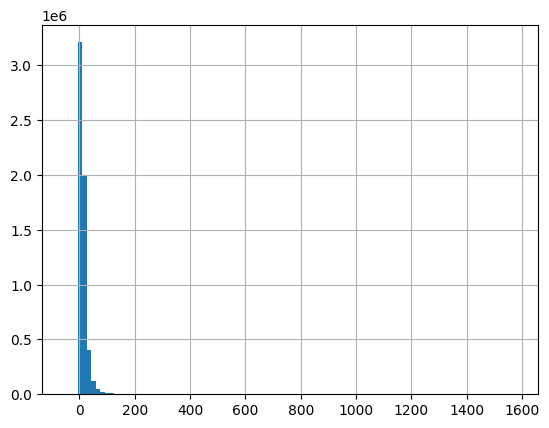

In [21]:
# Histogram

df["ride_duration_min"].hist(
    bins=100
)

<Axes: >

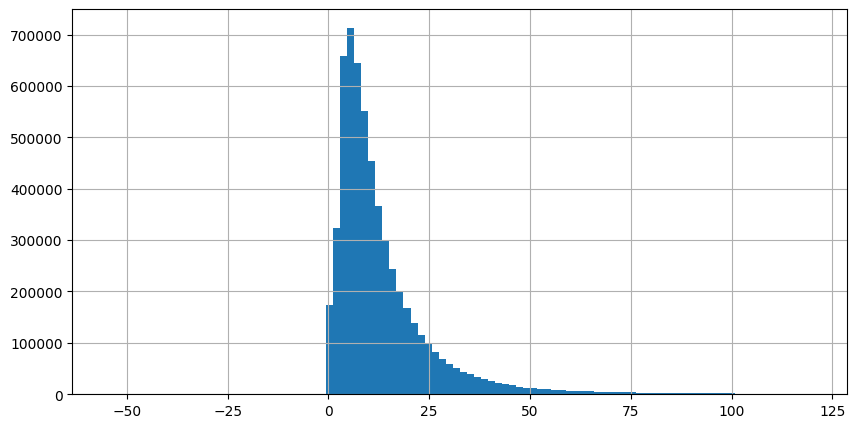

In [22]:
df.loc[
    df["ride_duration_min"] <= 120,
    "ride_duration_min"
].hist(
    bins=100,
    figsize=(10,5)
)

In [23]:
# Validation and inspection

# Negative duration
(df["ride_duration_min"] < 0).sum()
# 29 records contain negative value in "ride_duration_min"

df[df["ride_duration_min"] < 0]

# Missing value
df["ride_duration_min"].isna().sum()
# No missing value in "ride_duration_min"

# Zero duration
(df["ride_duration_min"] == 0).sum()
# No zero duration in "ride_duration_min"

# Less than 1 minute
(df["ride_duration_min"] < 1).sum()
# 161,323 records shorter than 1 min

# More than 24 hours
(df["ride_duration_min"] >= 1440).sum()
# 5,836 records longer than 24 hours

# Negative records are not physically possible, these records should be removed after inspection.
# Records with <1 min and >24 hours need further investigation to identify any possible patterns.

np.int64(5836)

### Removing records with negative duration

Finding
- 29 records (0.0005%) have negative ride durations, indicating that the recorded end time occurred before the start time.

Decision
- These records are considered as invalid and therefore, were removed from the dataset.

In [24]:
negative_duration = df["ride_duration_min"] < 0

df = df.loc[~negative_duration].copy()

### Further investigation: Trips shorter than 1 minute (Short trips)

Findings
- 161,323 trips (2.76% of all rides) lasted less than 1 minute.
- The distribution between casual riders and members was nearly identical. (49.1% vs 50.9%)
- All short trips were made with electric bike.
- 35640 trips (Approximately 22% of total short trips) started and ended at the same station.
- By comparing the dataset with and without the short trips, there are no significant differences in terms of the mean and median of ride duration.

Note: There are cases where same station name has multiple station IDs, therefore, "station_id"s, instead of "station_name"s were used to perform the inspection lead to the third observation.

Interpretation/Decision

- The exclusive occurrence among electric bikes suggests that these records may reflect some operational characteristics of electric bike rentals (for instance accidental or intentional ride cancellation, or billing issues), rather than data quality issues. Currently, there is no data for further investigation and insufficient evidence to verify these records as invalid trips. Therefore, these records were retained.

In [25]:
# Checking casual/member ratio

short_trip = df[df["ride_duration_min"] < 1]

print(
        short_trip["member_casual"]
        .value_counts()
)

print(
        short_trip["member_casual"]
        .value_counts(normalize=True)
)
print("")

# Checking bike type ratio
print(
        short_trip["rideable_type"]
        .value_counts()
)

print(
        short_trip["rideable_type"]
        .value_counts(normalize=True)
)
print("")

# Checking number of trips that started and ended at the same location
print(
        len(
            df[(df["ride_duration_min"] < 1) & (df["start_station_id"] == df["end_station_id"])]
        )
)

member_casual
casual    82105
member    79218
Name: count, dtype: int64
member_casual
casual    0.508948
member    0.491052
Name: proportion, dtype: float64

rideable_type
electric_bike    161323
Name: count, dtype: int64
rideable_type
electric_bike    1.0
Name: proportion, dtype: float64

35640


In [26]:
# Checking summary of trips less than 1 min

short_trip["ride_duration_min"].describe()

count    161323.000000
mean          0.376934
std           0.254942
min           0.000767
25%           0.172800
50%           0.326600
75%           0.539442
max           0.999983
Name: ride_duration_min, dtype: float64

<Axes: >

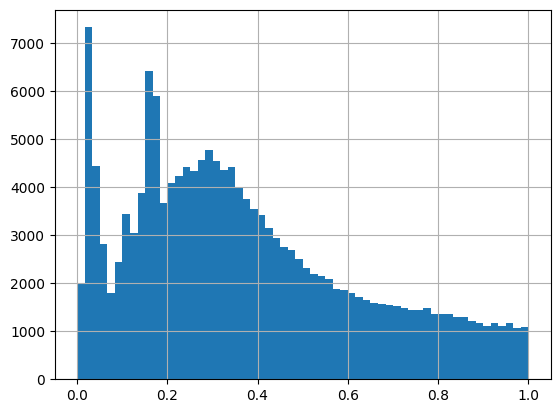

In [27]:
short_trip["ride_duration_min"].hist(
    bins=60
)

In [28]:
# Impact Analysis

before = (
    df
    .groupby("member_casual")["ride_duration_min"]
    .mean()
)

after = (
    df[df["ride_duration_min"] >= 1]
    .groupby("member_casual")["ride_duration_min"]
    .mean()
)

comparison = pd.concat(
    [before, after],
    axis=1
)

comparison.columns = [
    "Before Cleaning",
    "After removing <1 min"
]

comparison

,Before Cleaning,After removing <1 min
member_casual,,
casual,22.257821,23.147492
member,12.469995,12.731371


In [29]:
before_median = (
    df
    .groupby("member_casual")["ride_duration_min"]
    .median()
)

after_median = (
    df[df["ride_duration_min"] >= 1]
    .groupby("member_casual")["ride_duration_min"]
    .median()
)

comparison_median = pd.concat(
    [before_median, after_median],
    axis=1
)

comparison_median.columns = [
    "Before Cleaning",
    "After removing <1 min"
]

comparison_median

,Before Cleaning,After removing <1 min
member_casual,,
casual,11.270650,11.773233
member,8.590383,8.768967


### Further investigation of >24 hours trips (Long trips)

Findings
- 5,836 trips (0.10% of all rides) lasted longer than 24 hours.
- 82.3% of long trips were made by casual riders. (vs 17.7% members)
- All long trips were made with classic bike.
- 97.8% of long trips do not contain end station information.
- Trip durations were highly concentrated at around 25 hours.

Interpretation/Decision

- The unusual patterns - exclusively use of classic bike, highly concentrated trip durations and a high proportion of missing end station IDs, suggest that the records might be associated with system specific operational processes, rather than realistic riding behavior. The underlying cause cannot be verified with the dataset currently available, therefore, these records will be removed from behavioral analysis, to avoid data inaccuracy and introducing bias.

In [30]:
# Checking member/casual ratio

long_trip = df[df["ride_duration_min"] > 1440]

print(
        long_trip["member_casual"]
        .value_counts()
)

print(
        long_trip["member_casual"]
        .value_counts(normalize=True)
)
print("")

# Checking bike type ratio
print(
        long_trip["rideable_type"]
        .value_counts()
)

print(
        long_trip["rideable_type"]
        .value_counts(normalize=True)
)
print("")

# Checking number of trips that started and ended at the same location
print(
        len(
            df[(df["ride_duration_min"] > 1440) & (df["start_station_id"] == df["end_station_id"])]
        )
)



member_casual
casual    4805
member    1031
Name: count, dtype: int64
member_casual
casual    0.823338
member    0.176662
Name: proportion, dtype: float64

rideable_type
classic_bike    5836
Name: count, dtype: int64
rideable_type
classic_bike    1.0
Name: proportion, dtype: float64

27


In [31]:
long_trip["ride_duration_min"].describe()

count    5836.000000
mean     1499.239889
std         5.696471
min      1441.006333
25%      1499.663629
50%      1499.848008
75%      1499.904688
max      1574.900183
Name: ride_duration_min, dtype: float64

In [32]:
long_trip["start_station_id"].isna().mean()

np.float64(0.0)

In [33]:
long_trip["end_station_id"].isna().mean()

np.float64(0.9778958190541467)

In [34]:
long_trip["ended_at"].dt.hour.value_counts().sort_index()

ended_at
0     165
1     174
2     131
3     107
4      92
5      36
6      45
7      84
8     118
9     206
10    207
11    221
12    317
13    322
14    340
15    397
16    366
17    459
18    504
19    510
20    337
21    253
22    218
23    227
Name: count, dtype: int64

In [35]:
long_trip["started_at"].dt.hour.value_counts().sort_index()

started_at
0     174
1     131
2     104
3      95
4      35
5      46
6      81
7     117
8     206
9     212
10    216
11    310
12    325
13    341
14    399
15    368
16    452
17    511
18    510
19    337
20    255
21    217
22    228
23    166
Name: count, dtype: int64

In [36]:
long_trip["ended_at"] - long_trip["started_at"]

2845      1 days 00:59:55.983000
2942      1 days 00:59:39.878000
2978      1 days 00:59:51.264000
4414      1 days 00:59:54.427000
6452      1 days 00:46:11.789000
                   ...          
5814586   1 days 00:59:38.110000
5814660   1 days 00:59:47.256000
5814882   1 days 00:59:37.334000
5814907   1 days 00:59:47.745000
5814965   1 days 00:59:39.595000
Length: 5836, dtype: timedelta64[ns]

In [37]:
(
    long_trip["ride_duration_min"]
    -1440
).describe()

count    5836.000000
mean       59.239889
std         5.696471
min         1.006333
25%        59.663629
50%        59.848008
75%        59.904688
max       134.900183
Name: ride_duration_min, dtype: float64

<Axes: >

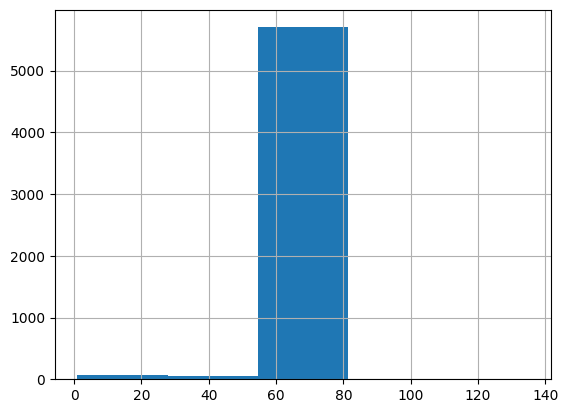

In [38]:
(
    long_trip["ride_duration_min"]
    -1440
).hist(
    bins=5
)

In [39]:
# Removing records with trip duration >24 hours

long_trip_mask = df["ride_duration_min"] > 1440

df = df.loc[~long_trip_mask].copy()

### Data Validation

In [40]:
df = df.reset_index(drop=True)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5842803 entries, 0 to 5842802
Data columns (total 15 columns):
 #   Column              Dtype          
---  ------              -----          
 0   ride_id             object         
 1   rideable_type       object         
 2   started_at          datetime64[ns] 
 3   ended_at            datetime64[ns] 
 4   start_station_name  object         
 5   start_station_id    object         
 6   end_station_name    object         
 7   end_station_id      object         
 8   start_lat           float64        
 9   start_lng           float64        
 10  end_lat             float64        
 11  end_lng             float64        
 12  member_casual       object         
 13  ride_duration       timedelta64[ns]
 14  ride_duration_min   float64        
dtypes: datetime64[ns](2), float64(5), object(7), timedelta64[ns](1)
memory usage: 668.7+ MB


In [41]:
df.shape

(5842803, 15)

In [42]:
df["ride_duration_min"].describe().round(2)

count    5842803.00
mean          14.50
std           28.92
min            0.00
25%            5.37
50%            9.39
75%           16.51
max         1439.98
Name: ride_duration_min, dtype: float64

In [43]:
(df["ride_duration_min"] < 0).sum()

np.int64(0)

In [44]:
(df["ride_duration_min"] > 1440).sum()

np.int64(0)

In [50]:
# Exporting cleaned dataset

from pathlib import Path

OUTPUT_PATH = Path("../00_Data/01_Interim")

OUTPUT_PATH.mkdir(
    parents=True,
    exist_ok=True
)

assert df["ride_duration_min"].min() >= 0
assert df["ride_duration_min"].max() < 1440
assert df["ride_id"].is_unique
assert df["started_at"].dtype == "datetime64[ns]"
assert df["ended_at"].dtype == "datetime64[ns]"

df.to_parquet(
    OUTPUT_PATH / "cyclistic_202506_202605_cleaned.parquet",
    index=False
)

In [ ]:
# Validation

test = pd.read_parquet(
    OUTPUT_PATH / "cyclistic_202506_202605_cleaned.parquet"
)

test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5842803 entries, 0 to 5842802
Data columns (total 15 columns):
 #   Column              Dtype          
---  ------              -----          
 0   ride_id             object         
 1   rideable_type       object         
 2   started_at          datetime64[ns] 
 3   ended_at            datetime64[ns] 
 4   start_station_name  object         
 5   start_station_id    object         
 6   end_station_name    object         
 7   end_station_id      object         
 8   start_lat           float64        
 9   start_lng           float64        
 10  end_lat             float64        
 11  end_lng             float64        
 12  member_casual       object         
 13  ride_duration       timedelta64[ns]
 14  ride_duration_min   float64        
dtypes: datetime64[ns](2), float64(5), object(7), timedelta64[ns](1)
memory usage: 668.7+ MB


In [53]:
assert test.shape == df.shape

assert list(test.columns) == list(df.columns)

In [54]:
print(f"""
Cleaning Completed

Rows    : {len(df):,}
Columns : {df.shape[1]}

Output:
{OUTPUT_PATH}
""")


Cleaning Completed

Rows    : 5,842,803
Columns : 15

Output:
..\00_Data\01_Interim

